In [1]:
import zipfile
import urllib.request
from pathlib import Path
import numpy as np
import pandas as pd
import seaborn as sns
from utils import numtostr
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter


raw_dir = Path("data/raw")
raw_dir.mkdir(parents = True, exist_ok = True)

zip_file = raw_dir / "online_retail.zip"
excel_file = raw_dir / "Online Retail.xlsx"

# 1. Download and extract if not already cached
if not excel_file.exists():
    url = "https://archive.ics.uci.edu/static/public/352/online+retail.zip"
    print("Downloading archive from UCI repository...")
    req = urllib.request.Request(url, headers = {"User-Agent": "Mozilla/5.0"})
    with urllib.request.urlopen(req) as resp, open(zip_file, "wb") as f:
        f.write(resp.read())
        
    print("Extracting workbook...")
    with zipfile.ZipFile(zip_file, "r") as z:
        z.extractall(raw_dir)
    print("Extraction complete.")

# 2. Ingest the uncompressed workbook
print("Loading Excel into DataFrame (takes ~15-25 seconds)...")
df_raw = pd.read_excel(excel_file, engine = "openpyxl")

print(f"Ingestion complete. Raw shape: {df_raw.shape}")
df_raw.head(5)

Loading Excel into DataFrame (takes ~15-25 seconds)...
Ingestion complete. Raw shape: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [2]:
# Calculating Gross Revenue From The Existing Data. 
df_raw["GrossRevenue"] = (df_raw["UnitPrice"] * df_raw["Quantity"]).round(2)
df_raw.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,GrossRevenue
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34


In [3]:
# So Here We Have NaN In Two Columns (Description), (CustomerID) In This Data_Frame,
df_raw.isna().sum()

InvoiceNo            0
StockCode            0
Description       1454
Quantity             0
InvoiceDate          0
UnitPrice            0
CustomerID      135080
Country              0
GrossRevenue         0
dtype: int64

In [4]:
# Since We Are Going To Do Analysis Based On Our Acquired Customers, So We Cannot Just Fill Anything Over Those Missing Customer_Id's,
# We Are Going To Seprate Those Anonymous/Unknown Customers Data.
ghost_df = df_raw[(df_raw["CustomerID"].isna())].copy()
ghost_df.head(5)
# We Got (135080) Transactions Where Customer-IDs Are Not Mentioned.

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,GrossRevenue
622,536414,22139,NaN,56,2010-12-01 11:52:00,0.00,NaN,United Kingdom,0.00
1443,536544,21773,DECORATIVE ROSE BATHROOM BOTTLE,1,2010-12-01 14:32:00,2.51,NaN,United Kingdom,2.51
1444,536544,21774,DECORATIVE CATS BATHROOM BOTTLE,2,2010-12-01 14:32:00,2.51,NaN,United Kingdom,5.02
1445,536544,21786,POLKADOT RAIN HAT,4,2010-12-01 14:32:00,0.85,NaN,United Kingdom,3.40
1446,536544,21787,RAIN PONCHO RETROSPOT,2,2010-12-01 14:32:00,1.66,NaN,United Kingdom,3.32


In [5]:
# Calculating The Gross Revenue, Coming From These Anonymous Transactions.
unattributed_gross_revenue = ghost_df["GrossRevenue"].sum()
print(unattributed_gross_revenue)
# So We Got (£1447682.12) This Amount Of Gross Revenue Coming From Those Anonymous Transactions.

1447682.12


In [6]:
total_gorss_revenue = df_raw["GrossRevenue"].sum()

In [7]:
# Lets See How Much This Contributes To The Total Companies Gross Revenue.
print(f"Total Companies Gross Revenue : {total_gorss_revenue}")
anonymous_prctg = ((unattributed_gross_revenue / total_gorss_revenue) * 100).round(2)
print(f"The Exact Metric Measuring How Much Money Is Generated By These Anonymous Transactions Is : {anonymous_prctg}%")

Total Companies Gross Revenue : 9747747.93
The Exact Metric Measuring How Much Money Is Generated By These Anonymous Transactions Is : 14.85%


In [8]:
tracked_net_sales = (df_raw.loc[~(df_raw["CustomerID"].isna()), "GrossRevenue"]).sum()

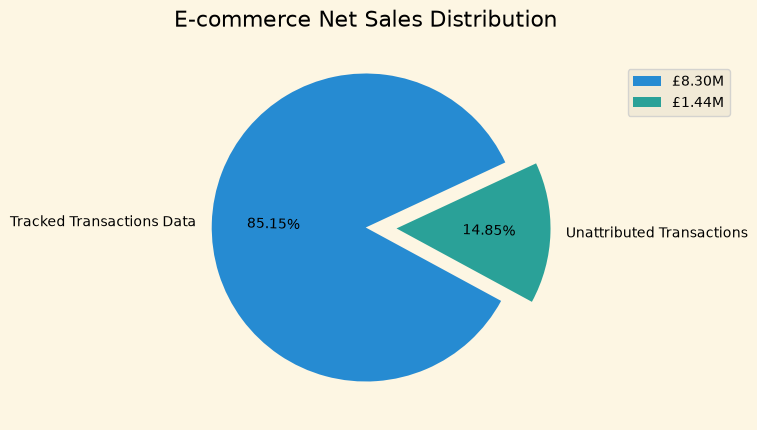

In [9]:
# plotting the gross revenue data in the chart to see the distribution.
revenues = [tracked_net_sales, unattributed_gross_revenue]

plt.style.use('Solarize_Light2')
fig, ax = plt.subplots(figsize = (15,5))
pie_plot = ax.pie(revenues, explode = [0, 0.2], labels = ["Tracked Transactions Data", "Unattributed Transactions"], startangle = +25)
plt.title("E-commerce Net Sales Distribution")
ax.pie_label(pie_plot, '{frac:.2%}', rotate = True)
ax.legend(numtostr(tracked_net_sales, unattributed_gross_revenue), loc = (1.18,0.79), fontsize = "medium")
plt.show()

In [10]:
# Now We Can Safely Remove Those Unknown Customers Data From Our Working Data_Frame.
df_raw = df_raw.dropna(subset = "CustomerID")

In [11]:
# Impute missing product descriptions with 'Unknown-Item' to preserve transaction records
# and keep unlabelled entries trackable during product-level aggregations.
df_raw["Description"] = df_raw["Description"].fillna("Unknown-Item")

In [12]:
df_raw.info()

<class 'pandas.DataFrame'>
Index: 406829 entries, 0 to 541908
Data columns (total 9 columns):
 #   Column        Non-Null Count   Dtype         
---  ------        --------------   -----         
 0   InvoiceNo     406829 non-null  object        
 1   StockCode     406829 non-null  object        
 2   Description   406829 non-null  object        
 3   Quantity      406829 non-null  int64         
 4   InvoiceDate   406829 non-null  datetime64[us]
 5   UnitPrice     406829 non-null  float64       
 6   CustomerID    406829 non-null  float64       
 7   Country       406829 non-null  str           
 8   GrossRevenue  406829 non-null  float64       
dtypes: datetime64[us](1), float64(3), int64(1), object(3), str(1)
memory usage: 36.2+ MB


<br><br>
### Important Explanation:
Since We Got Multiple Data Type Like Int/Str In This InvoiceNo Column, Pandas Convert This To An Object, Rather Than An Specific Type (Str/Int), <br>
And When We Try To Run An String Method With Str Accessor (df_raw.str.lower()), <br>
You May Think That Those Integer Values Will Be Converted Down To An String Value Like (Eg, "12346"), <br>
But Rather Than Doing That Pandas Simply Returns NaN For Those Integer Places, This Can Silently Break Your Code Logics, Even Though You May Think It Is Correct. <br>
So To Avoid This Behaviour We Explicitely Converted This Coulms Data Type To String, Those Integers Will Be Converted To Strings Like (Eg, "12346") <br>

In [13]:
# Managing The Data Type For These Columns (Quantity, UnitPrice, CustomerID, Description) To Save Up Ram Usage.
df_raw["Quantity"] = df_raw["Quantity"].astype("int32")
df_raw["UnitPrice"] = df_raw["UnitPrice"].astype("float32")
df_raw["CustomerID"] = df_raw["CustomerID"].astype("float32")
df_raw["Description"] = df_raw["Description"].astype("str") 
df_raw["InvoiceNo"] = df_raw["InvoiceNo"].astype("str") 

In [14]:
# Filtering Out Non-Merchandise Service Fee Codes From The Data.

# Here Are The List Of Those StockCodes That We Have To Filter Out From Our Data. 
non_service_codes = ['POST', 'D', 'M', 'BANK CHARGES', 'PADS', 'CR']
# First We Are Saving Those Non Service Tracnsactions Data.
non_service_transactions = df_raw[(df_raw["StockCode"].isin(non_service_codes))]
non_service_transactions.head(5)
# We Got (1754) Transactions Where StockCodes Are From Non Servicable Codes List.

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,GrossRevenue
45,536370,POST,POSTAGE,3,2010-12-01 08:45:00,18.00,12583.0,France,54.00
141,C536379,D,Discount,-1,2010-12-01 09:41:00,27.50,14527.0,United Kingdom,-27.50
386,536403,POST,POSTAGE,1,2010-12-01 11:27:00,15.00,12791.0,Netherlands,15.00
1123,536527,POST,POSTAGE,1,2010-12-01 13:04:00,18.00,12662.0,Germany,18.00
2239,536569,M,Manual,1,2010-12-01 15:35:00,1.25,16274.0,United Kingdom,1.25


In [15]:
# Now We Have To Check What Are The Appearance Percentage Of Each Of These Codes In Our Working Data_Frame.
codes_count = non_service_transactions["StockCode"].value_counts()
codes_prctg = (codes_count / df_raw["StockCode"].count()) * 100
codes_prctg

StockCode
POST            0.293981
M               0.114299
D               0.018927
BANK CHARGES    0.002950
PADS            0.000983
Name: count, dtype: float64

In [16]:
# Now That We Have Analyzes What We Have To, From The Non Service Stock Codes Data, We Can Now Safely Remove Those from Our Working Data Frame,
# Note: December 2011 Contains Incomplete Records.
# We Are Excluding It To Ensure Our Analysis Relies Only On Full-Month Data (Ending November 2011).
df_raw = df_raw[(~df_raw["StockCode"].isin(non_service_codes)) & (df_raw["InvoiceDate"] < "2011-12")]
df_all = df_raw.copy()

In [17]:
# Cancellation & Reversal Filtering, Excluding The Order InvoiceNo Entries That Starts With The Cancellation Indicator (C),
# As Well As Negative And Zero Quantity Entries To Isolate Genuine Completed Sales Order.
df_raw = df_raw[(~ (df_raw["Quantity"] <= 0)) & (~ (df_raw["InvoiceNo"].str.startswith("C")))]

In [18]:
# Now So That Our Data Frame Is Fully Cleaned, And Ready For The Analysis, We Can Drop Our df_raw Data_Frame.
df = df_raw
# Decremented The Reference Counter Of Our Raw Data Frame, This Should Eventually Remove The Entire Data Frame From The RAM. 
del df_raw

<br><br>
### Starting From Now We Will Analyze Our Data To Compute The Result That Will Be Helpfull In Answering Important Business Questions.

In [19]:
df_all["InvoiceMonth"] = pd.to_datetime(df_all["InvoiceDate"]).dt.to_period("M")
df_all.head(5)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,GrossRevenue,InvoiceMonth
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30,2010-12
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,2010-12
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00,2010-12
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,2010-12
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,2010-12


In [20]:
# Now Isolating The (Year-Month) From The InvoiceDate, As InvoiceMonth, This Is Solely For The Analysis Purpose.
df["InvoiceMonth"] = df["InvoiceDate"].dt.to_period("M")
df = df.rename(columns = {"GrossRevenue" : "NetRevenue"})
df.head(5)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,NetRevenue,InvoiceMonth
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30,2010-12
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,2010-12
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00,2010-12
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,2010-12
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,2010-12


In [21]:
# Finding The Acquisition Month Of Our Customer's.
AcquisitionMonth = df.groupby("CustomerID")[["InvoiceDate"]].min().reset_index()
AcquisitionMonth["InvoiceDate"] = AcquisitionMonth["InvoiceDate"].dt.to_period("M")
AcquisitionMonth = AcquisitionMonth.rename(columns = {"InvoiceDate" : "CohortMonth"})
# The December 2010 Cohort Acquired The Largest Volume Of New Customers, 
# Accounting For 884 Distinct Customer Made Thier First Transactions.

Acquisition_Month_Distribution = AcquisitionMonth["CohortMonth"].value_counts()
print(f"Here Is How Many New Customers We Gain In Each Cohort Month : \n{Acquisition_Month_Distribution}")
# Display The Cohort Sizes As Percentages Of The Total Customer Base
Acquisition_Month_Percentage_Distribution = (AcquisitionMonth["CohortMonth"].value_counts(normalize = True) * 100).round(2)
print(f"\nHere Is The Percentage Distribution For Each Cohort Month : \n{Acquisition_Month_Percentage_Distribution}")

Here Is How Many New Customers We Gain In Each Cohort Month : 
CohortMonth
2010-12    884
2011-03    452
2011-01    416
2011-02    380
2011-10    357
2011-11    324
2011-04    300
2011-09    299
2011-05    284
2011-06    242
2011-07    187
2011-08    169
Freq: M, Name: count, dtype: int64

Here Is The Percentage Distribution For Each Cohort Month : 
CohortMonth
2010-12    20.59
2011-03    10.53
2011-01     9.69
2011-02     8.85
2011-10     8.31
2011-11     7.55
2011-04     6.99
2011-09     6.96
2011-05     6.61
2011-06     5.64
2011-07     4.35
2011-08     3.94
Freq: M, Name: proportion, dtype: float64


In [22]:
# Formatting (Years) So That We Can Easily Distnguish Where We Started Our First Month Of This Year (Jan).
# Formatting This As (Dec-11, Jan-10) Like This. 
Acquisition_Month_Distribution = (Acquisition_Month_Distribution.reset_index()).sort_values(by = "CohortMonth")
Acquisition_Month_Distribution["CohortMonth"] = Acquisition_Month_Distribution["CohortMonth"].dt.strftime("%b-%y")
Acquisition_Month_Distribution

,CohortMonth,count
0,Dec-10,884
2,Jan-11,416
3,Feb-11,380
1,Mar-11,452
6,Apr-11,300
8,May-11,284
9,Jun-11,242
10,Jul-11,187
11,Aug-11,169
7,Sep-11,299


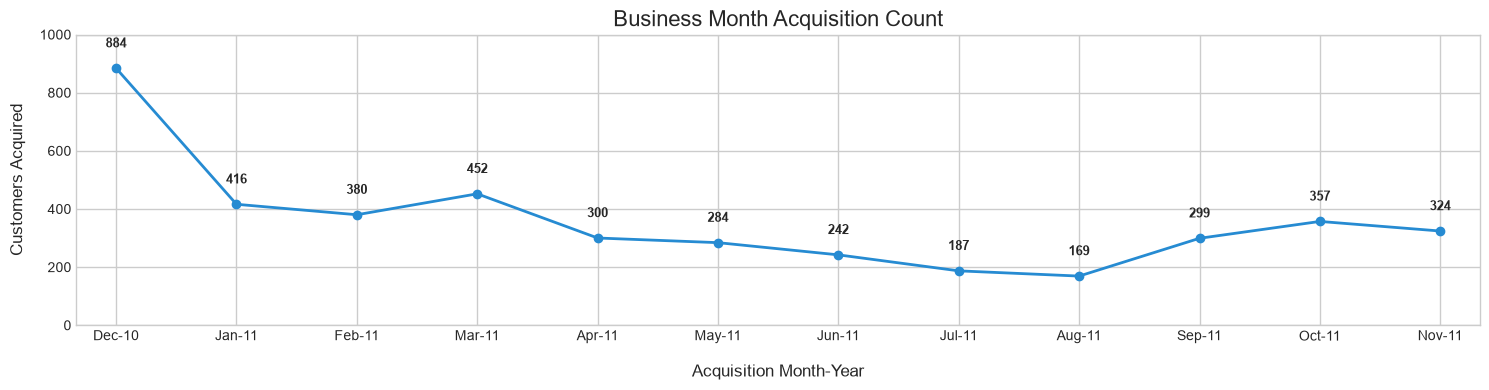

In [23]:
# here is the customer acquisition count for all the valid complete months from the data. 
plt.style.use("seaborn-v0_8-whitegrid")
fig, ax = plt.subplots(figsize = (15,4))
ax.plot(Acquisition_Month_Distribution["CohortMonth"], Acquisition_Month_Distribution["count"], marker = "o")
plt.grid(True)
ax.set(title = "Business Month Acquisition Count")
ax.set_ylabel("Customers Acquired", labelpad = 10)
ax.set_xlabel("Acquisition Month-Year", labelpad = 15)
ax.set_ylim(0, 1000)
ax.margins(x = 0.03)
plt.tight_layout()

for x, y in zip(Acquisition_Month_Distribution["CohortMonth"], Acquisition_Month_Distribution["count"]):
    ax.annotate(f"{y}", xy = (x, y), xytext = (0, 15), ha = "center", textcoords = "offset points", fontsize = 9, fontweight = "bold")

<br><br>
## Customer Acquisition Trend:

### Observation :
Customer acquisition peaks at 884 in Dec-2010 (where we have acquired our future VIP customers in a large count, in that period),
Which continues till the end of the Q1 of the (2011 Jan to Mar), (this VIP acquisition is tested bellow in this notebook).

### Implication :
So again we have that window coming up, where we have to again pivot our marketing strategies to acquire those VIP customers (this group account for almost 73.80% of our entire gross sales),

### Possible next step : 
so we have to analyze our previous strategy that we uses previous year, to bring those heavy spenders,
so we can capture them in this upcoming window as well.

In [24]:
df = pd.merge(df, AcquisitionMonth, on = "CustomerID", how = "left")
df.head(5)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,NetRevenue,InvoiceMonth,CohortMonth
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30,2010-12,2010-12
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,2010-12,2010-12
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00,2010-12,2010-12
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,2010-12,2010-12
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,2010-12,2010-12


In [25]:
Active_Customers_Transactions = df.groupby(["CustomerID", "InvoiceMonth"])[["CohortMonth"]].min().reset_index()
Active_Customers_Transactions["Index_Month"] = Active_Customers_Transactions["InvoiceMonth"].astype(int) - Active_Customers_Transactions["CohortMonth"].astype(int)
Active_Customers_Transactions.head(5)

,CustomerID,InvoiceMonth,CohortMonth,Index_Month
0,12346.0,2011-01,2011-01,0
1,12347.0,2010-12,2010-12,0
2,12347.0,2011-01,2010-12,1
3,12347.0,2011-04,2010-12,4
4,12347.0,2011-06,2010-12,6


In [26]:
df = pd.merge(df, Active_Customers_Transactions, on = ["CustomerID", "InvoiceMonth", "CohortMonth"], how = "left")
df.head(5)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,NetRevenue,InvoiceMonth,CohortMonth,Index_Month
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30,2010-12,2010-12,0
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,2010-12,2010-12,0
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00,2010-12,2010-12,0
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,2010-12,2010-12,0
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,2010-12,2010-12,0


In [27]:
# Customer Retention Headcount Matrix: Built the cohort-by-month grid tracking the absolute number of active unique customers over time.   
Retention_HeadCount = df.groupby(["CohortMonth", "Index_Month"])[["CustomerID"]].nunique().unstack().droplevel(axis = 1, level = 0)
Retention_HeadCount

Index_Month,0,1,2,3,4,5,6,7,8,9,10,11
CohortMonth,,,,,,,,,,,,
2010-12,884.0,323.0,286.0,339.0,320.0,352.0,320.0,308.0,312.0,349.0,330.0,444.0
2011-01,416.0,91.0,111.0,95.0,132.0,120.0,103.0,100.0,123.0,136.0,152.0,NaN
2011-02,380.0,71.0,71.0,109.0,103.0,93.0,97.0,104.0,94.0,116.0,NaN,NaN
2011-03,452.0,67.0,114.0,90.0,101.0,76.0,121.0,104.0,126.0,NaN,NaN,NaN
2011-04,300.0,63.0,61.0,63.0,59.0,68.0,65.0,78.0,NaN,NaN,NaN,NaN
2011-05,284.0,54.0,49.0,49.0,59.0,66.0,75.0,NaN,NaN,NaN,NaN,NaN
2011-06,242.0,42.0,38.0,64.0,56.0,80.0,NaN,NaN,NaN,NaN,NaN,NaN
2011-07,187.0,33.0,38.0,42.0,51.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2011-08,169.0,34.0,41.0,41.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [28]:
Cohorts_Aquisition = Retention_HeadCount[0]
Retention_In_Percentage = (Retention_HeadCount.div(Cohorts_Aquisition, axis = 0) * 100).round(2)
Retention_In_Percentage

Index_Month,0,1,2,3,4,5,6,7,8,9,10,11
CohortMonth,,,,,,,,,,,,
2010-12,100.0,36.54,32.35,38.35,36.20,39.82,36.20,34.84,35.29,39.48,37.33,50.23
2011-01,100.0,21.88,26.68,22.84,31.73,28.85,24.76,24.04,29.57,32.69,36.54,NaN
2011-02,100.0,18.68,18.68,28.68,27.11,24.47,25.53,27.37,24.74,30.53,NaN,NaN
2011-03,100.0,14.82,25.22,19.91,22.35,16.81,26.77,23.01,27.88,NaN,NaN,NaN
2011-04,100.0,21.00,20.33,21.00,19.67,22.67,21.67,26.00,NaN,NaN,NaN,NaN
2011-05,100.0,19.01,17.25,17.25,20.77,23.24,26.41,NaN,NaN,NaN,NaN,NaN
2011-06,100.0,17.36,15.70,26.45,23.14,33.06,NaN,NaN,NaN,NaN,NaN,NaN
2011-07,100.0,17.65,20.32,22.46,27.27,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2011-08,100.0,20.12,24.26,24.26,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


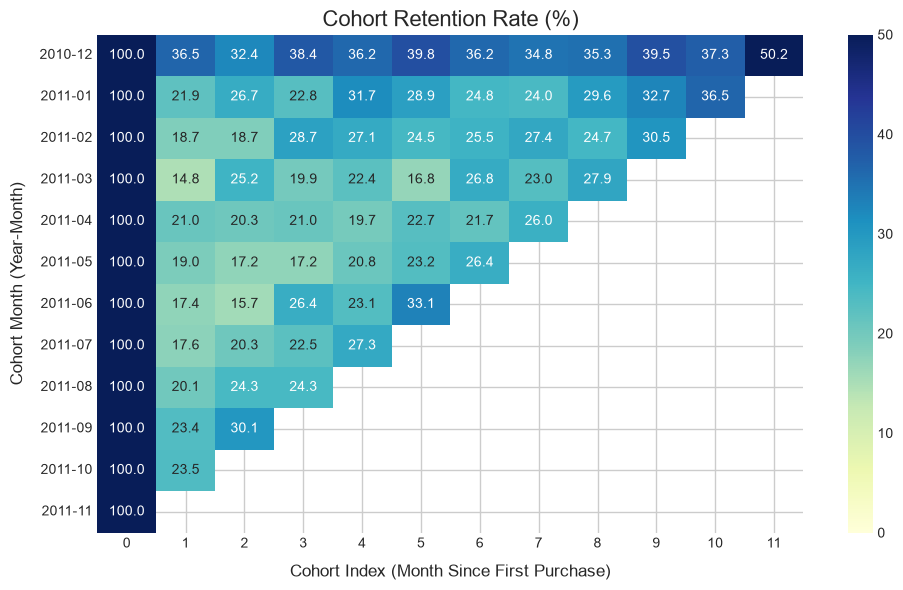

In [29]:
plt.figure(figsize=(10, 6))
sns.heatmap(Retention_In_Percentage, annot = True, fmt = ".1f", vmin = 0.0, vmax = 50.0, cmap = "YlGnBu")
plt.title("Cohort Retention Rate (%)")
plt.ylabel("Cohort Month (Year-Month)", labelpad = 10)
plt.xlabel("Cohort Index (Month Since First Purchase)", labelpad = 10)
plt.tight_layout()
plt.show()

<br><br>
- ### Observation: 
Across the Q1 to Q3 cohorts of 2011, we see a severe retention decline in Month 1, 
dropping into the (14.8% to 23.4%) range. However, if a customer survives past Month 2, 
their retention stabilizes into a consistent baseline.

- ### Implication:
We are successfully acquiring customers through marketing but failing to transition them into repeat buyers,
The first 30 days are the critical failure point.

- ### Possible Next Step: 
Implement an retention campaign. 
If we trigger vouchers, discounts, or re-engagement emails before the 30-day mark,
we can bridge this drop-off. Once they make that second purchase,
the data shows they are highly likely to remain in our active customer base.

<br>

- ### Observation:
Furthermore, the December 2010 cohort showed incredible long-term loyalty,
peaking at a massive 50.2% retention in Month 11 (November 2011).

- ### Implication:
This suggests that Q4 acquisitions are likely annual holiday or wholesale shoppers returning for the next season.

- ### Data Limitation & Possible Next Step: 
Because we only have a single month of historical Q4 data (Dec 2010), 
we must be careful not to over-extrapolate. Before shifting our entire budget to Q4, 
we need to query whether that December 2010 cohort was influenced by a unique external event,
(e.g., a new branch opening or a major category launch).

In [30]:
Business_Month_Gross_Revenue = ((df_all.groupby("InvoiceMonth")[["GrossRevenue"]].sum()).reset_index()).sort_values(by = "InvoiceMonth")
Business_Month_Gross_Revenue = Business_Month_Gross_Revenue.rename(columns = {"InvoiceMonth" : "MonthlyPeriod"})
Business_Month_Gross_Revenue["SalesMonthYear"] = Business_Month_Gross_Revenue["MonthlyPeriod"].dt.strftime("%b-%y")
Business_Month_Gross_Revenue["FormattedLabels"] = numtostr(*(tuple(Business_Month_Gross_Revenue["GrossRevenue"])))
Business_Month_Gross_Revenue

,MonthlyPeriod,GrossRevenue,SalesMonthYear,FormattedLabels
0,2010-12,550675.08,Dec-10,£550.67K
1,2011-01,472922.82,Jan-11,£472.92K
2,2011-02,435230.25,Feb-11,£435.23K
3,2011-03,575226.45,Mar-11,£575.22K
4,2011-04,422352.95,Apr-11,£422.35K
5,2011-05,651989.65,May-11,£651.98K
6,2011-06,642279.85,Jun-11,£642.27K
7,2011-07,581840.89,Jul-11,£581.84K
8,2011-08,614254.61,Aug-11,£614.25K
9,2011-09,925337.28,Sep-11,£925.33K


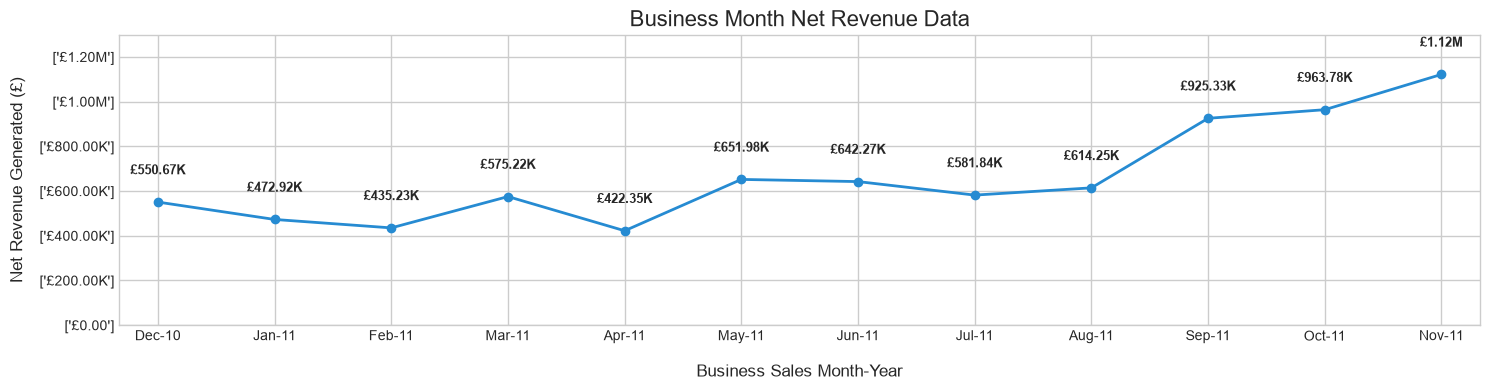

In [31]:
plt.style.use("seaborn-v0_8-whitegrid")
fig, ax = plt.subplots(figsize = (15,4))
ax.plot(Business_Month_Gross_Revenue["SalesMonthYear"], Business_Month_Gross_Revenue["GrossRevenue"], marker = "o")
plt.grid(True)
ax.set(title = "Business Month Net Revenue Data")
ax.set_ylabel("Net Revenue Generated (£)", labelpad = 10)
ax.set_xlabel("Business Sales Month-Year", labelpad = 15)
ax.yaxis.set_major_formatter(FuncFormatter(lambda val, pos: numtostr(val)))
ax.set_ylim(0 , 1_300_000)

ax.margins(x = 0.03)
plt.tight_layout()

for x, y, label in zip(Business_Month_Gross_Revenue["SalesMonthYear"], Business_Month_Gross_Revenue["GrossRevenue"], Business_Month_Gross_Revenue["FormattedLabels"]):
    ax.annotate(
        label,                        
        xy=(x, y),                    
        xytext=(0, 20),
        textcoords="offset points",
        ha="center",
        fontsize=9,
        fontweight="bold"
    )

<br><br>
## Observation:
Monthly net sales jumps from £550.67K in Dec 2010 to £1.12M in Nov 2011, roughly doubling. Because we dont have last year's Q4 sales data, and November is a holiday-peak month, One year of data can't separate them, so we cannot compare them as year over year growth.

## Implication: 
The rise starts in September, when net sales jumped £311.08K over August, the largest month-to-month increase in the period, This chart can't tell us which customer base drove this saled. **We tested it whether it came from top spenders or the wider customer base in the Pareto Contribution section below.**

## Possible next step: 
If the Sep-Nov ramp is seasonal, holiday campaigns and stock planning would need to start earlier (July/August). Treat this as a hypothesis, and test it with a second year of data before changing plans.

In [32]:
AcquisitionMonth

,CustomerID,CohortMonth
0,12346.0,2011-01
1,12347.0,2010-12
2,12348.0,2010-12
3,12349.0,2011-11
4,12350.0,2011-02
...,...,...
4289,18280.0,2011-03
4290,18281.0,2011-06
4291,18282.0,2011-08
4292,18283.0,2011-01


In [33]:
df_all = pd.merge(df_all, AcquisitionMonth, on = "CustomerID", how = "left")
df_all["Index_Month"] = (df_all["InvoiceMonth"].astype(int) - df_all["CohortMonth"].astype(int))

In [34]:
Aquired_Customers_Lifetime_Revenue = (df_all.loc[(df_all["Index_Month"] >= 0)]).groupby(["CohortMonth", "Index_Month"])[["GrossRevenue"]].sum().unstack().droplevel(axis=1, level=0)
Aquired_Customers_Lifetime_Revenue
# Cohort Net Revenue Matrix: A Matrix Displaying The Total Monthly Sales Revenue Generated By Distinct Customer Cohorts Over Their Lifecycle.

Index_Month,0,1,2,3,4,5,6,7,8,9,10,11
CohortMonth,,,,,,,,,,,,
2010-12,554593.09,266379.58,227123.79,291477.01,196955.45,321275.93,305857.21,302576.52,308202.01,459552.75,426552.23,495415.9
2011-01,207702.94,52550.96,61552.99,40827.22,79201.73,82453.44,68278.97,71051.71,70962.32,102420.20,120748.37,NaN
2011-02,155922.05,26792.31,38568.07,47873.57,38259.38,32282.28,49229.80,59061.03,54126.59,63184.12,NaN,NaN
2011-03,195445.04,27196.08,57429.39,41105.06,49750.36,39204.86,63895.85,62550.73,68504.77,NaN,NaN,NaN
2011-04,118814.63,28353.68,24520.89,23989.39,25862.54,28970.49,27914.10,33646.11,NaN,NaN,NaN,NaN
2011-05,117872.35,17855.72,19322.26,18549.04,27334.62,32336.10,32408.63,NaN,NaN,NaN,NaN,NaN
2011-06,132252.25,13599.39,13110.70,29609.87,25510.48,40065.13,NaN,NaN,NaN,NaN,NaN,NaN
2011-07,72050.22,10874.27,14905.73,17148.47,18809.32,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2011-08,78169.68,19468.84,32657.06,40474.95,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [35]:
# Aggregating All-Time Cumulative Revenue Generated By Each Cohort Group.
# Note: Older Cohorts Will Naturally Skew Higher As They Have Had More Months To Accumulate Spend.
Revenue_Generated_By_Cohort = Aquired_Customers_Lifetime_Revenue.sum(axis = 1).reset_index().rename(columns = {0 : "TotalRevenue"})
Revenue_Generated_By_Cohort

,CohortMonth,TotalRevenue
0,2010-12,4155961.47
1,2011-01,957750.85
2,2011-02,565299.20
3,2011-03,605082.14
4,2011-04,312071.83
5,2011-05,265678.72
6,2011-06,254147.82
7,2011-07,133788.01
8,2011-08,170770.53
9,2011-09,212865.61


In [36]:
Aquired_Customers_Cumulative_Revenue = Aquired_Customers_Lifetime_Revenue.cumsum(axis = 1)
Aquired_Customers_Cumulative_Revenue

Index_Month,0,1,2,3,4,5,6,7,8,9,10,11
CohortMonth,,,,,,,,,,,,
2010-12,554593.09,820972.67,1048096.46,1339573.47,1536528.92,1857804.85,2163662.06,2466238.58,2774440.59,3233993.34,3660545.57,4155961.47
2011-01,207702.94,260253.90,321806.89,362634.11,441835.84,524289.28,592568.25,663619.96,734582.28,837002.48,957750.85,NaN
2011-02,155922.05,182714.36,221282.43,269156.00,307415.38,339697.66,388927.46,447988.49,502115.08,565299.20,NaN,NaN
2011-03,195445.04,222641.12,280070.51,321175.57,370925.93,410130.79,474026.64,536577.37,605082.14,NaN,NaN,NaN
2011-04,118814.63,147168.31,171689.20,195678.59,221541.13,250511.62,278425.72,312071.83,NaN,NaN,NaN,NaN
2011-05,117872.35,135728.07,155050.33,173599.37,200933.99,233270.09,265678.72,NaN,NaN,NaN,NaN,NaN
2011-06,132252.25,145851.64,158962.34,188572.21,214082.69,254147.82,NaN,NaN,NaN,NaN,NaN,NaN
2011-07,72050.22,82924.49,97830.22,114978.69,133788.01,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2011-08,78169.68,97638.52,130295.58,170770.53,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [37]:
# Cohort Lifetime Value (LTV) Growth: Tracks How The Average Value Of A Customer Scales Over Their Lifecycle,
# While this dataset does not contain marketing spend, 
# Combining these cohort LTV benchmarks with internal Customer Acquisition Cost (CAC) data would allow the business to model exact CAC payback periods.
Customer_LTV = Aquired_Customers_Cumulative_Revenue.div(Cohorts_Aquisition, axis = 0).round(2)
Customer_LTV

Index_Month,0,1,2,3,4,5,6,7,8,9,10,11
CohortMonth,,,,,,,,,,,,
2010-12,627.37,928.70,1185.63,1515.35,1738.15,2101.59,2447.58,2789.86,3138.51,3658.36,4140.89,4701.31
2011-01,499.29,625.61,773.57,871.72,1062.11,1260.31,1424.44,1595.24,1765.82,2012.03,2302.29,NaN
2011-02,410.32,480.83,582.32,708.31,808.99,893.94,1023.49,1178.92,1321.36,1487.63,NaN,NaN
2011-03,432.40,492.57,619.63,710.57,820.63,907.37,1048.73,1187.12,1338.68,NaN,NaN,NaN
2011-04,396.05,490.56,572.30,652.26,738.47,835.04,928.09,1040.24,NaN,NaN,NaN,NaN
2011-05,415.04,477.92,545.95,611.27,707.51,821.37,935.49,NaN,NaN,NaN,NaN,NaN
2011-06,546.50,602.69,656.87,779.22,884.64,1050.20,NaN,NaN,NaN,NaN,NaN,NaN
2011-07,385.30,443.45,523.16,614.86,715.44,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2011-08,462.54,577.74,770.98,1010.48,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [38]:
Earning_From_Each_Customers = df_all.groupby("CustomerID")[["GrossRevenue"]].sum().reset_index().rename(columns = {"GrossRevenue" : "CustomerValue"})
Earning_From_Each_Customers.head()

,CustomerID,CustomerValue
0,12346.0,0.00
1,12347.0,4085.18
2,12348.0,1437.24
3,12349.0,1457.55
4,12350.0,294.40


In [39]:
# This Should Get Me The Count Of 20% Of Our Customer Base. 
Top_20_Percent_Headcount  = (Earning_From_Each_Customers["CustomerID"].count() * 0.20).round().astype("int")
print(f"20% Customer HeadCount : {Top_20_Percent_Headcount}")

20% Customer HeadCount : 864


In [40]:
# Extract the top 20% highest-value Customers Based On Their Historical Lifetime Spend.
# This Subset Represents Our Most Valuable Buyer Tier For Premium Revenue Analysis.
Top_Tier_CustomersID = Earning_From_Each_Customers.sort_values(by = "CustomerValue", ascending = False).head(Top_20_Percent_Headcount)
top_20_prct_buyers_id = list(Top_Tier_CustomersID["CustomerID"])
Top_Tier_CustomersID.head(10)

,CustomerID,CustomerValue
1682,14646.0,267050.00
4184,18102.0,248171.76
3714,17450.0,188173.13
1873,14911.0,126030.76
54,12415.0,123638.18
1328,14156.0,114505.32
3757,17511.0,80758.88
3163,16684.0,60518.14
990,13694.0,59792.94
2168,15311.0,58352.77


In [41]:
sales_data_of_Remaining_80_prct = df_all.loc[(~(df_all["CustomerID"].isin(top_20_prct_buyers_id))), "GrossRevenue"].sum()
sales_data_of_top_20_prct = Top_Tier_CustomersID["CustomerValue"].sum()
revenue_distribution = [sales_data_of_Remaining_80_prct, sales_data_of_top_20_prct]
revenue_distribution

[np.float64(2085638.6099999999), np.float64(5871865.850000001)]

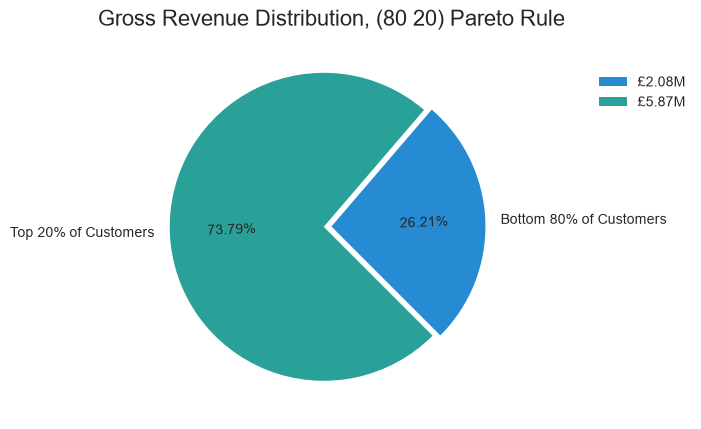

In [42]:
fig, ax = plt.subplots(figsize = (15,5))
pie_plot = ax.pie(revenue_distribution, explode = (0,0.05), labels = ["Bottom 80% of Customers", "Top 20% of Customers"], startangle = -45)
ax.set_title("Gross Revenue Distribution, (80 20) Pareto Rule")
ax.pie_label(pie_plot, '{frac:.2%}', rotate = True)
ax.legend(numtostr(revenue_distribution[0], revenue_distribution[1]), loc = (1.18,0.79), fontsize = "medium")

<br><br>
### Observation:
There is a pareto (80 20) distribution in our chart, even though we have (73.80 26.20),
where 73.80% of entire business gross sales comes from top-20% buyers,

### Implication:
While the top 20% segment generates nearly 3x the total revenue of the bottom 80% (73.80% vs 26.20%), on a per-customer basis a top-tier buyer generates roughly 11x the revenue of a standard buyer.

### Possible Next step:
So we should give an special treatment to those customers,
something like a gift or special treatment specially for VIP members,
that reduces the likely hood of loosing those customers.

In [43]:
len(top_20_prct_buyers_id)

864

In [44]:
df_all.loc[(df_all["InvoiceMonth"].dt.month.isin([9, 10, 11])) & (df_all["CustomerID"].notna()), "GrossRevenue"].sum()

np.float64(3010731.91)

In [45]:
last_months_sales_data = df_all.loc[(df_all["InvoiceMonth"].dt.month.isin([9, 10, 11]))]
last_months_sales_data.head(5)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,GrossRevenue,InvoiceMonth,CohortMonth,Index_Month
230985,565080,20677,PINK POLKADOT BOWL,8,2011-09-01 08:25:00,1.25,13509.0,United Kingdom,10.0,2011-09,2011-02,7
230986,565080,22128,PARTY CONES CANDY ASSORTED,24,2011-09-01 08:25:00,1.25,13509.0,United Kingdom,30.0,2011-09,2011-02,7
230987,565082,22423,REGENCY CAKESTAND 3 TIER,2,2011-09-01 09:15:00,12.75,13305.0,United Kingdom,25.5,2011-09,2010-12,9
230988,565082,15060B,FAIRY CAKE DESIGN UMBRELLA,8,2011-09-01 09:15:00,3.75,13305.0,United Kingdom,30.0,2011-09,2010-12,9
230989,565082,23245,SET OF 3 REGENCY CAKE TINS,4,2011-09-01 09:15:00,4.95,13305.0,United Kingdom,19.8,2011-09,2010-12,9


In [46]:
top_20_prct_contribution = last_months_sales_data.loc[(last_months_sales_data["CustomerID"].isin(top_20_prct_buyers_id)), "CustomerID"]
top_20_prct_contribution = top_20_prct_contribution.drop_duplicates()
top_20_prct_contribution = pd.merge(last_months_sales_data, top_20_prct_contribution, on = "CustomerID", how = "right")
sum(top_20_prct_contribution["GrossRevenue"])

2114218.66

In [47]:
remaining_80_prct_contibution = last_months_sales_data.loc[(~last_months_sales_data["CustomerID"].isin(top_20_prct_buyers_id)), 'CustomerID']
remaining_80_prct_contibution = remaining_80_prct_contibution.drop_duplicates()
remaining_80_prct_contibution = pd.merge(last_months_sales_data, remaining_80_prct_contibution, on = "CustomerID", how = "right")
sum(remaining_80_prct_contibution["GrossRevenue"])

896513.25

In [48]:
# Choosing these month's (Sep, Oct, Nov) from our data because we have seen that these months sales are hiked then others,
# to check if top-20% buyers have any influence to that sales number.
B2B_Buyers_Id = last_months_sales_data.loc[(last_months_sales_data["Index_Month"] > 0) & (last_months_sales_data["GrossRevenue"] > 20.0) & (last_months_sales_data["Quantity"] > 12), "CustomerID"]
B2B_Buyers_Id = B2B_Buyers_Id.drop_duplicates()
top_20_guaranteed = B2B_Buyers_Id[B2B_Buyers_Id.isin(top_20_prct_buyers_id)]
len(top_20_guaranteed)

# so we can see that from (864) our top-20% customer's who make 74% of our gross revenue, from those (712) customers shows up again in these month's (Sep, Oct, Nov).
# where in these month's alone we have generated roughly (£3.01M) of gross sales,
# and from that our regular customer's including newer acquired customers in those month's accounts for (£896.51K) roughly (29.7%) in gross sales,
# and our top-20% customers (864) accounts for (£2.1M) roughly (70.3%) in gross sales,

712

In [49]:
Top_Tier_Customers_info = (df_all.loc[(df_all["CustomerID"].isin(top_20_prct_buyers_id))])

In [50]:
# Extract Unique Profile Data For Top-Tier Customers And Append Their Total Lifetime Value.
# The Resulting DataFrame Is Sorted In Descending Order To Prioritize Our Highest-Value VIP Accounts.
# Note: This Is An Optional Diagnostic Step To Inspect The Complete Operational Profiles Of Our Top Buyers.

first_invoice = df.sort_values("InvoiceDate").drop_duplicates("CustomerID")[["CustomerID", "InvoiceNo"]]
first_order_value = (df.merge(first_invoice, on = ["CustomerID", "InvoiceNo"]).groupby("CustomerID")[["NetRevenue"]].sum()).reset_index()
top_tier_customer_first_order_value = ((first_order_value.loc[(first_order_value["CustomerID"].isin(Top_Tier_CustomersID["CustomerID"]))]).rename(columns = {"NetRevenue" : "First_Purchase_value"})).sort_values(by = "First_Purchase_value", ascending = False, ignore_index = True)
top_tier_customer_first_order_value

,CustomerID,First_Purchase_value
0,15749.0,15160.90
1,18102.0,9639.12
2,12590.0,9341.26
3,14088.0,7544.91
4,12415.0,7011.38
...,...,...
859,12474.0,29.50
860,14096.0,21.84
861,12476.0,12.45
862,14285.0,5.90


In [51]:
Top_Tier_Cohort_Distribution = Top_Tier_Customers_info.groupby("CohortMonth")[["CustomerID"]].nunique().reset_index().rename(columns = {"CustomerID" : ""})
Top_Tier_Cohort_Distribution

,CohortMonth,
0,2010-12,388
1,2011-01,126
2,2011-02,85
3,2011-03,101
4,2011-04,42
5,2011-05,36
6,2011-06,25
7,2011-07,13
8,2011-08,8
9,2011-09,22


In [52]:
top_tier_customer_ltv = Top_Tier_Customers_info.groupby("CustomerID").agg(Customer_Value = ("GrossRevenue", "sum")).reset_index()
top_tier_customer_value_against_first_transaction = (pd.merge(top_tier_customer_ltv, top_tier_customer_first_order_value, on = "CustomerID", how = 'left')).sort_values(by = "First_Purchase_value", ascending = False)
top_tier_customer_value_against_first_transaction.sort_values(by = "Customer_Value", ascending = False)

,CustomerID,Customer_Value,First_Purchase_value
391,14646.0,267050.00,55.96
839,18102.0,248171.76,9639.12
752,17450.0,188173.13,39.60
429,14911.0,126030.76,540.38
15,12415.0,123638.18,7011.38
...,...,...,...
67,12633.0,1906.63,904.82
719,17228.0,1906.09,183.30
588,16150.0,1906.07,393.42
551,15819.0,1905.45,639.64


In [53]:
(top_tier_customer_value_against_first_transaction["First_Purchase_value"]).mean()

np.float64(758.0456597222221)

In [54]:
(top_tier_customer_value_against_first_transaction["First_Purchase_value"]).median()

np.float64(469.19)

In [55]:
(top_tier_customer_value_against_first_transaction["First_Purchase_value"]).quantile(0.25)

np.float64(307.3925)

<br><br>
### High-Value Buyers Start Big From Order-1:
**Observation:** We tested the hypothesis of whether our top-tier B2B buyers initiated their lifecycle with micro transaction or substantial opening orders. Data of our first order value of top-20% customer reveals a median first-order value of £469.19 (IQR: £308.60 – £853.73, minimum: £4.95), 50% of future VIPs placed opening orders above £474, scaling to generate Lifetime Values (LTV) between £1,900 and £267.05K. <br><br>
**Implication:** High-value B2B buyers self-identify on their very first purchase through larger basket sizes.<br><br>
**Actionable Next Step:** Use First Order Value (e.g., opening invoices £300) as an early lead-scoring threshold to flag high-potential accounts immediately after their first purchase, assigning dedicated account management and proactive follow-ups to secure repeat bulk orders.

In [56]:
tracked = df_all.dropna(subset=["CustomerID"]).copy()
tracked["is_vip"] = tracked["CustomerID"].isin(top_20_prct_buyers_id)

gross_sales = tracked.loc[tracked["GrossRevenue"] > 0].groupby("is_vip")["GrossRevenue"].sum()
refunds = tracked.loc[tracked["GrossRevenue"] < 0].groupby("is_vip")["GrossRevenue"].sum().abs()

return_summary = pd.DataFrame({
    "Gross_Sales_£": gross_sales,
    "Refunds_£": refunds,
    "Return_Rate_%": (refunds / gross_sales * 100).round(2)
})
return_summary.index = ["Remaining 80% Buyers", "Top 20% VIPs"]
return_summary

,Gross_Sales_£,Refunds_£,Return_Rate_%
Remaining 80% Buyers,2220577.21,134938.60,6.08
Top 20% VIPs,6044102.11,172236.26,2.85


In [57]:
returners = tracked.loc[tracked["GrossRevenue"] < 0].groupby("is_vip")["CustomerID"].nunique()
total_cust = tracked.groupby("is_vip")["CustomerID"].nunique()
print((returners / total_cust * 100).round(2).rename({False: "Remaining 80% (% who ever returned)", True: "Top 20% VIPs (% who ever returned)"}))

is_vip
Remaining 80% (% who ever returned)    26.00
Top 20% VIPs (% who ever returned)     69.21
Name: CustomerID, dtype: float64


<br><br>
## Return & Refund Dynamics
* **Observation:** While **69.21%** of Top 20% VIP customers logged at least one return or invoice adjustment (compared to **26.00%** of regular buyers), high order frequency keeps VIP revenue refund leakage at less than half that of the remaining 80% segment (**2.85%** of gross sales vs. **6.08%** for regular buyers). <br><br>
* **Implication:** High return incidence among VIPs reflects frequent repeat purchasing rather than severe financial erosion—their returns create minimal top-line leakage relative to their total spend. Conversely, The remaining 80% segment loses a larger share of its sales to returns and cancellations (6.08% vs 2.85%, about 2.1x), even though far fewer of its customers ever return anything (26.00% vs 69.21%). The data doesn't show why. One hypothesis is that a few large one-off orders were later cancelled. We check this below by looking at the largest return invoices.<br><br>
* **Recommended Next Steps:**
  * **Curb Non-VIP Leakage:** Audit high-value cancellations among regular buyers and tighten order confirmation or restocking rules on large one-off orders to reduce the **6.08%** gross revenue leakage.
  * **Investigate VIP Return Drivers (Hypothesis):** Even though a **2.85%** refund rate has limited immediate balance-sheet impact, recurring returns across **69.21%** of VIP accounts could signal underlying SKU defects, fulfillment errors, or friction that risks long-term VIP churn. Categorize VIP credit notes by `StockCode` and return reason to determine whether this is routine bulk-order adjustment or a solvable product issue.

In [58]:
# 1) Which invoices drive the refunds? (is_vip is in the index; True = VIP)
neg = tracked[tracked["GrossRevenue"] < 0]
print(neg.groupby(["is_vip", "InvoiceNo"])["GrossRevenue"].sum().sort_values().head(10))

# 2) Refund rate when VIPs are defined by GROSS purchases (before returns), which removes the circularity
gross_by_cust = tracked.loc[tracked["GrossRevenue"] > 0].groupby("CustomerID")["GrossRevenue"].sum()
vip_gross_ids = gross_by_cust.index[gross_by_cust >= gross_by_cust.quantile(0.8)]
tracked["vip_gross"] = tracked["CustomerID"].isin(vip_gross_ids)
g = tracked.loc[tracked["GrossRevenue"] > 0].groupby("vip_gross")["GrossRevenue"].sum()
r = tracked.loc[tracked["GrossRevenue"] < 0].groupby("vip_gross")["GrossRevenue"].sum().abs()
print((r / g * 100).round(2))

is_vip  InvoiceNo
False   C541433     -77183.60
True    C550456     -22998.40
        C570556     -11816.64
        C562375      -4345.10
        C565044      -3969.93
        C567527      -3825.36
False   C571499      -3528.34
True    C564940      -3491.02
        C572343      -2949.28
        C569743      -2924.00
Name: GrossRevenue, dtype: float64
vip_gross
False    2.22
True     4.24
Name: GrossRevenue, dtype: float64


<br><br>
## Bulk Cancellation Outlier & Classification Bias

* **Observation:** A single cancelled wholesale order (`InvoiceNo C541433`, **-£77,183.60**) accounted for **57.19%** of all refund value in the regular customer segment. Because VIP tiers were originally defined using net LTV, this customer dropped into the regular buyer bucket after cancelling inflating the regular segment's refund rate to **6.08%**. When segments are defined by gross purchase volume prior to returns (`vip_gross`), high-spend buyers actually exhibit nearly double the refund rate of regular buyers (**4.24%** vs. **2.22%**).
* **Implication:** The low refund rate in the net-VIP tier was distorted by survivorship/classification bias: large wholesale prospects who placed massive orders and subsequently cancelled were pushed out of the VIP group, skewing the remaining 80% segment. In reality, bulk wholesale orders carry the highest financial cancellation exposure.
* **Recommended Next Steps:**
  * **Monitor & Guard High-Value Bulk Orders:** While occasional order cancellations are normal in wholesale operations, single reversals exceeding £10K–£75K materially distort gross revenue. Implement pre-dispatch confirmation checks, partial deposits, or dedicated account-manager sign-offs on unusually large orders to reduce wholesale cancellation leakage before fulfillment.

In [59]:
m = (
    tracked.groupby(["InvoiceMonth", "is_vip"])["GrossRevenue"]
    .sum()
    .unstack()
)

print("Monthly VIP Share (%):")
print((m[True] / m.sum(axis=1) * 100).round(1))

print("\nAug -> Sep Net Revenue Jump (£):")
print(m.diff().loc["2011-09"])

Monthly VIP Share (%):
InvoiceMonth
2010-12    75.8
2011-01    78.1
2011-02    74.4
2011-03    75.4
2011-04    69.7
2011-05    76.1
2011-06    78.6
2011-07    76.3
2011-08    77.1
2011-09    72.0
2011-10    69.9
2011-11    69.0
Freq: M, dtype: float64

Aug -> Sep Net Revenue Jump (£):
is_vip
False    118051.28
True     193031.39
Name: 2011-09, dtype: float64


<br><br>
## Pareto Contribution (80/20) Breakdown

* **Observation:** Top 20% VIP customers sustain a **69.0% to 78.6%** share of monthly net revenue across the entire year (generating **73.6%** of total tracked revenue). This disproves the hypothesis that VIPs are purely seasonal Q4 bulk buyers—they form a consistent, year-round revenue backbone from Q1 through Q4.
  <br><br>
* **Implication:** The August-to-September revenue surge was broad-based rather than VIP-exclusive: while VIP spend jumped by **+£193.0K** in September, the remaining 80% segment simultaneously grew by **+£118.1K** and continued accelerating through October and November (diluting VIP share from **77.1%** in August to **69.0%** in November). Because the dataset ends in November 2011 (right-censored horizon), we cannot yet separate one-time Q4 holiday shoppers from newly acquired buyers who will mature into future VIPs.
  <br><br>
* **Recommended Next Steps:**
  * **Replicate December Acquisition Playbook:** Because the `2010-12` cohort produced our highest volume of long-term VIPs, audit the acquisition channels, product bundles, and promotions active during December 2010 to deploy ahead of the upcoming Q4 window.
  * **Introduce Tiered High-AOV Incentives:** Since future VIPs typically enter with significantly higher first-order values, launch cart-threshold incentives (e.g., volume discounts or priority shipping on large initial order totals) during Q4 to capture and lock in high-value wholesale buyers.

In [60]:
# Grouping The Dataset To Find Every Unique Date On Which A Specific Customer Made A Purchase, Ignoring Multiple Items Bought On The Same Inoive/Bill.
Customers_All_Unique_Transactions_Details = df.groupby(["CustomerID", "InvoiceDate"])[["InvoiceNo"]].min().reset_index()

# Filter The Timeline To Completely Remove One-Time Buyers And Isolate Customers Who Have Come Back To Make Their Second Purchase.
Customer_With_Only_Repeat_Purchases = Customers_All_Unique_Transactions_Details.groupby("CustomerID").filter(lambda x: len(x) > 1)

# Organizes Each Customer's History In Perfect Chronological Order So We Can Track Their Timeline From Their Very First Visit Onward.
Customer_With_Only_Repeat_Purchases = Customer_With_Only_Repeat_Purchases.sort_values(by = ["CustomerID", "InvoiceDate"], ignore_index = True)
Customer_With_Only_Repeat_Purchases = Customer_With_Only_Repeat_Purchases.drop("InvoiceNo", axis = 1)
Customer_With_Only_Repeat_Purchases.head(5)

,CustomerID,InvoiceDate
0,12347.0,2010-12-07 14:57:00
1,12347.0,2011-01-26 14:30:00
2,12347.0,2011-04-07 10:43:00
3,12347.0,2011-06-09 13:01:00
4,12347.0,2011-08-02 08:48:00


In [61]:
# Create A Sequence Counter That Numbers Each Customer's Shopping Visits (1st Purchase, 2nd Purchase, 3rd Purchase, etc.) Over Their Lifetime.
Customer_With_Only_Repeat_Purchases["Order_Count"] = Customer_With_Only_Repeat_Purchases.groupby(["CustomerID"])[["InvoiceDate"]].rank(method = "dense").astype("int")
Customer_With_Only_Repeat_Purchases.head(5)

,CustomerID,InvoiceDate,Order_Count
0,12347.0,2010-12-07 14:57:00,1
1,12347.0,2011-01-26 14:30:00,2
2,12347.0,2011-04-07 10:43:00,3
3,12347.0,2011-06-09 13:01:00,4
4,12347.0,2011-08-02 08:48:00,5


In [62]:
# Striping Away All Later Transactions And Keeping Only The Records For The First Two Purchases A Customer Ever Made.
First_To_Second_Order_Only = Customer_With_Only_Repeat_Purchases[(Customer_With_Only_Repeat_Purchases["Order_Count"] <= 2)]
First_To_Second_Order_Only.head(5)

,CustomerID,InvoiceDate,Order_Count
0,12347.0,2010-12-07 14:57:00,1
1,12347.0,2011-01-26 14:30:00,2
6,12348.0,2010-12-16 19:09:00,1
7,12348.0,2011-01-25 10:42:00,2
10,12352.0,2011-02-16 12:33:00,1


In [63]:
# Rearrange The Layout So That Each Customer Occupies A Single Row With Their First Purchase Date And Second Purchase Date Lined Up Side-By-Side.
First_To_Second_Order_Only = First_To_Second_Order_Only.pivot(index = "CustomerID", columns = "Order_Count", values = "InvoiceDate").rename(columns = {1 : "FirstOrder", 2 : "SecondOrder"})
First_To_Second_Order_Only.columns.name = None
First_To_Second_Order_Only.head(5)

,FirstOrder,SecondOrder
CustomerID,,
12347.0,2010-12-07 14:57:00,2011-01-26 14:30:00
12348.0,2010-12-16 19:09:00,2011-01-25 10:42:00
12352.0,2011-02-16 12:33:00,2011-03-01 14:57:00
12356.0,2011-01-18 09:50:00,2011-04-08 12:33:00
12359.0,2011-01-12 12:43:00,2011-02-07 14:51:00


In [64]:
# Calculating The Exact Number Of Days That Passed Between A Customer's First Purchase And Their Second Return Visit.
# This Reveals The Actual Re-Acquisition Velocity Of Our Loyal Customer Base.
Customers_First_To_Second_Order_Duration = ((First_To_Second_Order_Only["SecondOrder"]) - (First_To_Second_Order_Only["FirstOrder"])).dt.days.astype("int")
Customers_First_To_Second_Order_Duration.head(5)

CustomerID
12347.0    49
12348.0    39
12352.0    13
12356.0    80
12359.0    26
dtype: int64

In [65]:
print(Customers_First_To_Second_Order_Duration.mean().round(2),"Days")
print(Customers_First_To_Second_Order_Duration.median(),"Days")
print(Customers_First_To_Second_Order_Duration.describe().round(2))

75.6 Days
50.0 Days
count    2740.00
mean       75.60
std        75.37
min         0.00
25%        19.75
50%        50.00
75%       111.00
max       364.00
dtype: float64


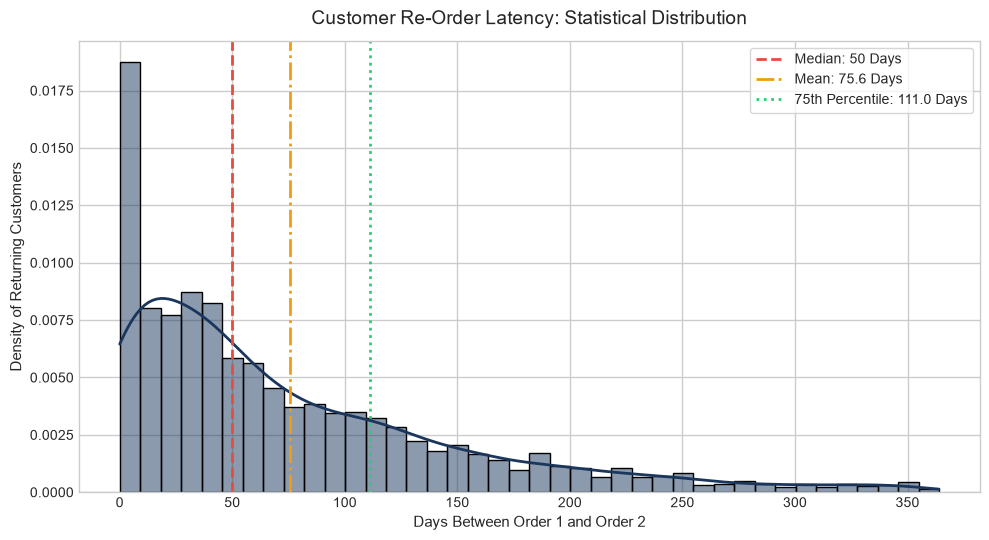

In [66]:
# Clean the series of any missing values if present
latency = Customers_First_To_Second_Order_Duration.dropna()

mean_val = latency.mean()
median_val = latency.median()
q75_val = latency.quantile(0.75)

fig, ax_hist = plt.subplots(figsize = (10, 5.5))

sns.histplot(latency, kde = True, ax = ax_hist, color = "#1B365D", bins = 40, stat = "density")

# Overlaying the exact statistical markers as vertical reference lines
ax_hist.axvline(median_val, color="#E74C3C", linestyle = "--", linewidth = 2, label = f"Median: {median_val:.0f} Days",)
ax_hist.axvline(mean_val, color = "#F39C12", linestyle = "-.", linewidth = 2, label = f"Mean: {mean_val:.1f} Days",)
ax_hist.axvline(q75_val, color = "#2ECC71", linestyle = ":", linewidth = 2, label = f"75th Percentile: {q75_val:.1f} Days",)

ax_hist.set_title("Customer Re-Order Latency: Statistical Distribution", fontsize = 14, pad = 12)
ax_hist.set_xlabel("Days Between Order 1 and Order 2", fontsize = 11)
ax_hist.set_ylabel("Density of Returning Customers", fontsize = 11)
ax_hist.legend(frameon = True, facecolor = "white", loc = "upper right")

plt.tight_layout()
plt.show()

### Key Business Insights: Order Latency & Segment Purchasing Cycles
* **Observation:** Among repeat customers, the median time between the first and second purchase is 50 days.
* **Implication:** High Customer Acquisition Cost (CAC) becomes a sunk cost if we lose buyers before their second purchase. Bridging them past Month 1 is critical to stabilizing long-term retention.
* **Actionable Next Step (CRM Escalation Workflow):** 
  * **Day 25:** Send a low-cost engagement trigger (e.g., product recommendations, educational content) as a gentle brand reminder.
  * **Day 45:** For customers who still have not purchased, trigger a discount coupon. This aggressive offer intercepts them right before the 50-day cliff to secure the second purchase.